# 03 · Data Summarization and Visualization
**Module 4 (CO3)** — Bike Sharing Demand EDA

| Syllabus topic | Section |
|---|---|
| Statistical summary measures, data elaboration | §1, §2 |
| 1-D statistical data analysis | §3 |
| 2-D statistical data analysis | §4 |
| Contingency tables | §5 |
| n-D statistical data analysis | §6 |
| Visualization: scatter plots, dot charts, bar plots | §7 |

We mainly use the **daily** dataset (731 days) here, which is easier to summarise than hourly data.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from utils import (set_style, save_fig, load_clean_daily, load_clean_hourly,
                   PALETTE, SEASONS, WEATHER, WEEKDAYS, SEQ_CMAP)

set_style()
daily = load_clean_daily()
hourly = load_clean_hourly()
print("daily:", daily.shape, "| hourly:", hourly.shape)
daily.head()

daily: (731, 14) | hourly: (17379, 19)


,year,month,season,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,cnt
date,,,,,,,,,,,,,,
2011-01-01,2011,1,Spring,0,Sat,0,Clear,14.11,18.18,80.46,13.92,331,654,985
2011-01-02,2011,1,Spring,0,Sun,0,Mist/Cloudy,14.90,17.68,69.61,16.65,131,670,801
2011-01-03,2011,1,Spring,0,Mon,1,Clear,8.05,9.47,43.73,16.95,120,1229,1349
2011-01-04,2011,1,Spring,0,Tue,1,Clear,8.20,10.61,59.04,11.02,108,1454,1562
2011-01-05,2011,1,Spring,0,Wed,1,Clear,9.31,11.46,43.70,13.15,82,1518,1600


## 1. Statistical summary measures
| Group | Measures |
|---|---|
| Central tendency | mean, median, mode, trimmed mean |
| Dispersion | range, variance, standard deviation, IQR, coefficient of variation, MAD |
| Shape | skewness, kurtosis |
| Position | min, percentiles, max |

In [2]:
def summary(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
        "trimmed mean (10%)": stats.trim_mean(s, 0.1),
        "range": s.max() - s.min(), "variance": s.var(), "std": s.std(),
        "IQR": q3 - q1, "CV (%)": s.std() / s.mean() * 100,
        "MAD": stats.median_abs_deviation(s),
        "skewness": s.skew(), "kurtosis": s.kurt(),
        "min": s.min(), "P10": s.quantile(0.1), "P90": s.quantile(0.9), "max": s.max(),
    })

cols = ["cnt", "casual", "registered", "temp", "humidity", "windspeed"]
summary_table = daily[cols].apply(summary).round(2)
summary_table

,cnt,casual,registered,temp,humidity,windspeed
mean,4504.35,848.18,3656.17,20.31,62.80,13.83
median,4548.00,713.00,3662.00,20.43,62.65,12.96
mode,1096.00,120.00,1707.00,10.90,63.08,9.92
trimmed mean (10%),4517.19,744.95,3641.72,20.38,62.73,13.36
range,8692.00,3408.00,6926.00,32.85,97.62,27.46
variance,3752788.21,471450.44,2434399.96,56.35,202.68,20.11
std,1937.21,686.62,1560.26,7.51,14.24,4.48
IQR,2804.00,780.50,2279.50,13.08,20.86,5.64
CV (%),43.01,80.95,42.67,36.96,22.67,32.42
MAD,1407.00,396.00,1155.00,6.49,10.35,2.77


**Reading the table**
- Daily total rentals average **≈ 4,504**, with median ≈ 4,548 — almost symmetric (skew ≈ 0) at the daily level, unlike the skewed hourly data.
- **Casual** riders are far more variable (CV ≈ 81%) and right-skewed than **registered** riders (CV ≈ 43%): casual use depends on weather and weekends.
- Humidity has the smallest relative spread; windspeed is mildly right-skewed.

## 2. Data elaboration
Elaboration means *understanding and enriching* the data: checking types and cardinality, and deriving new, more informative variables.

In [3]:
elab = pd.DataFrame({"dtype": daily.dtypes.astype(str), "n_unique": daily.nunique(),
                     "example": daily.iloc[0]})
elab

,dtype,n_unique,example
year,int64,2,2011
month,int64,12,1
season,str,4,Spring
holiday,int64,2,0
weekday,str,7,Sat
workingday,int64,2,0
weather,str,3,Clear
temp,float64,593,14.11
atemp,float64,540,18.18
humidity,float64,635,80.46


In [4]:
# Derived variables
daily["casual_share"] = (daily["casual"] / daily["cnt"] * 100).round(2)  # % of rides by casual users
daily["feels_diff"] = (daily["atemp"] - daily["temp"]).round(2)          # wind-chill / heat effect
daily["day_type"] = np.where(daily["workingday"] == 1, "Working day", "Weekend/Holiday")
daily[["cnt", "casual_share", "feels_diff", "day_type"]].head()

,cnt,casual_share,feels_diff,day_type
date,,,,
2011-01-01,985,33.60,4.07,Weekend/Holiday
2011-01-02,801,16.35,2.78,Weekend/Holiday
2011-01-03,1349,8.90,1.42,Working day
2011-01-04,1562,6.91,2.41,Working day
2011-01-05,1600,5.12,2.15,Working day


In [5]:
daily.groupby("day_type")[["cnt", "casual", "registered", "casual_share"]].mean().round(1)

,cnt,casual,registered,casual_share
day_type,,,,
Weekend/Holiday,4330.2,1371.1,2959.0,29.1
Working day,4584.8,606.6,3978.2,12.3


On weekends and holidays casual riders make up **~29%** of rides vs **~12%** on working days, while total demand is similar — so the *mix* of users changes more than the volume.

## 3. 1-D statistical data analysis
Analysing one variable: frequency distribution, shape, and checking normality.

In [6]:
# Frequency distribution table
bins = range(0, 9001, 1000)
freq = pd.cut(daily["cnt"], bins=bins).value_counts().sort_index()
freq_table = pd.DataFrame({"frequency": freq, "relative (%)": (freq / freq.sum() * 100).round(1),
                           "cumulative (%)": (freq.cumsum() / freq.sum() * 100).round(1)})
freq_table

,frequency,relative (%),cumulative (%)
cnt,,,
"(0, 1000]",19,2.6,2.6
"(1000, 2000]",79,10.8,13.4
"(2000, 3000]",74,10.1,23.5
"(3000, 4000]",107,14.6,38.2
"(4000, 5000]",166,22.7,60.9
"(5000, 6000]",106,14.5,75.4
"(6000, 7000]",86,11.8,87.1
"(7000, 8000]",82,11.2,98.4
"(8000, 9000]",12,1.6,100.0


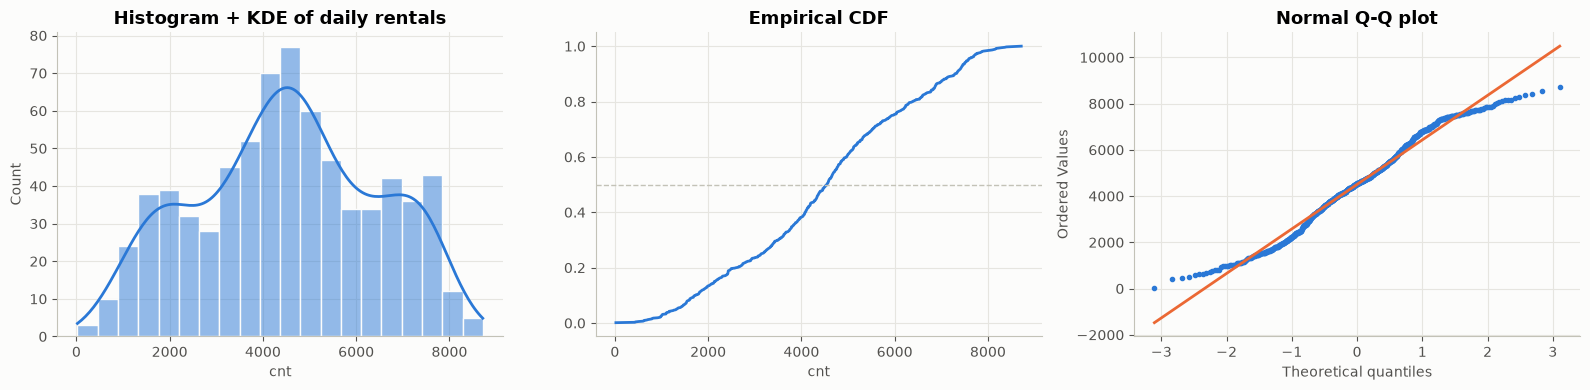

Shapiro-Wilk: W = 0.9801, p = 2.08e-08


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(daily["cnt"], bins=20, kde=True, color=PALETTE[0], ax=axes[0], edgecolor="#fcfcfb")
axes[0].set_title("Histogram + KDE of daily rentals")

x = np.sort(daily["cnt"])
axes[1].plot(x, np.arange(1, len(x) + 1) / len(x), color=PALETTE[0])
axes[1].axhline(0.5, color="#c3c2b7", linestyle="--", linewidth=1)
axes[1].set_title("Empirical CDF")
axes[1].set_xlabel("cnt")

stats.probplot(daily["cnt"], dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(color=PALETTE[0], markersize=3)
axes[2].get_lines()[1].set(color=PALETTE[1])
axes[2].set_title("Normal Q-Q plot")
fig.tight_layout()
save_fig(fig, "03_one_d")
plt.show()

w, p = stats.shapiro(daily["cnt"])
print(f"Shapiro-Wilk: W = {w:.4f}, p = {p:.2e}")

The histogram is broad and flat-topped (negative kurtosis) — a mix of low-demand winter days and high-demand summer days. The Q-Q plot bends at both ends and Shapiro–Wilk rejects normality.

## 4. 2-D statistical data analysis
Two variables together: covariance, correlation, grouped statistics and joint distributions.

In [8]:
print("Covariance matrix:")
display(daily[["temp", "humidity", "cnt"]].cov().round(1))
print("Correlation matrix:")
display(daily[["temp", "humidity", "cnt"]].corr().round(3))

Covariance matrix:


,temp,humidity,cnt
temp,56.4,13.7,9124.7
humidity,13.7,202.7,-2750.6
cnt,9124.7,-2750.6,3752788.2


Correlation matrix:


,temp,humidity,cnt
temp,1.000,0.128,0.627
humidity,0.128,1.000,-0.100
cnt,0.627,-0.100,1.000


In [9]:
daily.groupby("season")["cnt"].agg(["count", "mean", "median", "std", "min", "max"]).reindex(SEASONS).round(0)

,count,mean,median,std,min,max
season,,,,,,
Spring,181,2604.0,2209.0,1400.0,431,7836
Summer,184,4992.0,4942.0,1696.0,795,8362
Fall,188,5644.0,5354.0,1460.0,1115,8714
Winter,178,4728.0,4634.0,1700.0,22,8555


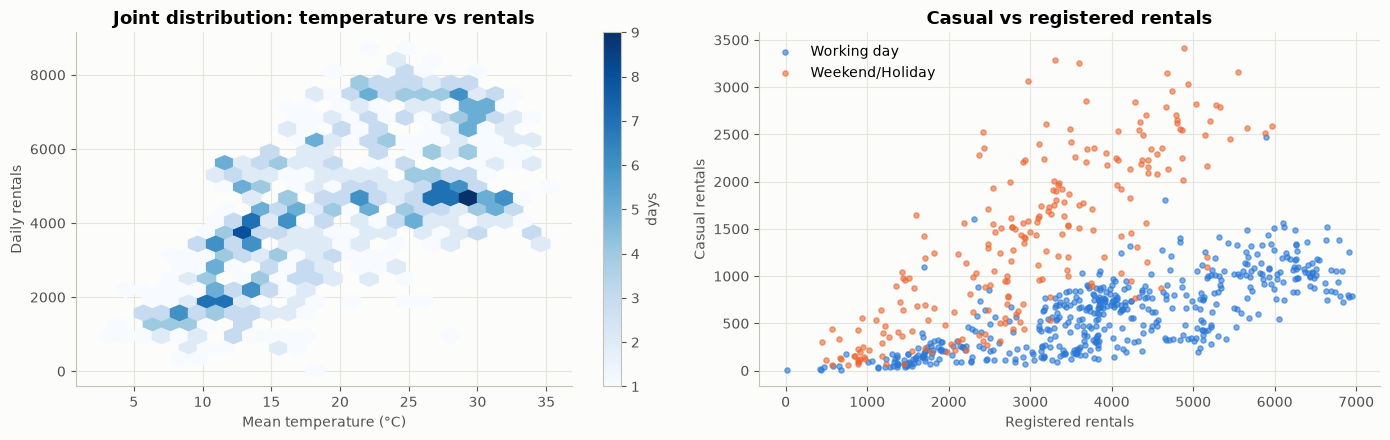

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hb = axes[0].hexbin(daily["temp"], daily["cnt"], gridsize=25, cmap=SEQ_CMAP, mincnt=1)
fig.colorbar(hb, ax=axes[0], label="days")
axes[0].set_xlabel("Mean temperature (°C)")
axes[0].set_ylabel("Daily rentals")
axes[0].set_title("Joint distribution: temperature vs rentals")

for i, dt in enumerate(["Working day", "Weekend/Holiday"]):
    d = daily[daily.day_type == dt]
    axes[1].scatter(d["registered"], d["casual"], s=14, alpha=0.6, color=PALETTE[i], label=dt)
axes[1].set_xlabel("Registered rentals")
axes[1].set_ylabel("Casual rentals")
axes[1].set_title("Casual vs registered rentals")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "03_two_d")
plt.show()

The casual–registered scatter splits into **two clear bands**: on weekends casual use is high relative to registered use; on working days the reverse.

## 5. Contingency tables
A contingency table (cross-tabulation) counts how often combinations of two categorical variables occur. The **χ² test of independence** checks whether they are related, and **Cramér's V** measures the strength (0 = none, 1 = perfect).

In [11]:
ct = pd.crosstab(daily["season"], daily["weather"], margins=True, margins_name="Total")
ct = ct.reindex(SEASONS + ["Total"])[WEATHER + ["Total"]]
ct

weather,Clear,Mist/Cloudy,Rain/Snow,Total
season,,,,
Spring,131,41,9,181
Summer,140,36,8,184
Fall,159,25,4,188
Winter,117,48,13,178
Total,547,150,34,731


In [12]:
# Row percentages: within each season, what share of days had each weather type?
(pd.crosstab(daily["season"], daily["weather"], normalize="index") * 100).reindex(SEASONS)[WEATHER].round(1)

weather,Clear,Mist/Cloudy,Rain/Snow
season,,,
Spring,72.4,22.7,5.0
Summer,76.1,19.6,4.3
Fall,84.6,13.3,2.1
Winter,65.7,27.0,7.3


In [13]:
def chi2_report(table, name):
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    print(f"{name}: χ² = {chi2:.1f}, dof = {dof}, p = {p:.3g}, Cramér's V = {v:.3f}")
    return expected

expected = chi2_report(pd.crosstab(daily["season"], daily["weather"]), "Season × Weather (daily)")
ct2 = pd.crosstab(hourly["temp_band"], hourly["demand_level"]).reindex(
    index=["Cold", "Mild", "Warm", "Hot"], columns=["Low", "Medium", "High", "Very High"])
_ = chi2_report(ct2, "Temp band × Demand level (hourly)")

Season × Weather (daily): χ² = 18.7, dof = 6, p = 0.00461, Cramér's V = 0.113
Temp band × Demand level (hourly): χ² = 3082.0, dof = 9, p = 0, Cramér's V = 0.243


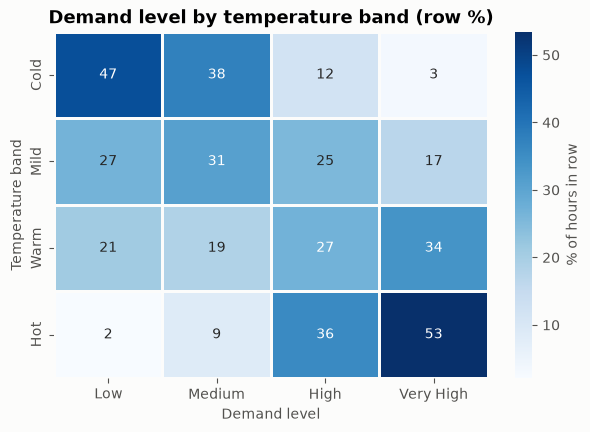

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(ct2.div(ct2.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap=SEQ_CMAP,
            linewidths=1, linecolor="#fcfcfb", cbar_kws={"label": "% of hours in row"}, ax=ax)
ax.set_title("Demand level by temperature band (row %)")
ax.set_xlabel("Demand level")
ax.set_ylabel("Temperature band")
save_fig(fig, "03_contingency_heatmap")
plt.show()

- **Season × weather:** p ≈ 0.005 → statistically significant, but **weak** (Cramér's V ≈ 0.11): winter has more misty/rainy days and fall more clear days.
- **Temperature × demand:** strongly associated. In cold hours ~half of hours are "Low" demand; in hot hours over half are "Very High" (moderate association, V ≈ 0.24).

## 6. n-D statistical data analysis
Three or more variables at once: multi-way pivot tables, multi-level grouping and faceted (small-multiple) plots.

In [15]:
pivot = daily.pivot_table(index="season", columns=["day_type", "weather"], values="cnt",
                          aggfunc="mean").reindex(SEASONS).round(0)
pivot

day_type Weekend/Holiday                       Working day              \
weather            Clear Mist/Cloudy Rain/Snow       Clear Mist/Cloudy   
season                                                                   
Spring            2378.0      1896.0    1587.0      3027.0      2464.0   
Summer            5541.0      4120.0    2200.0      5223.0      4081.0   
Fall              5618.0      4618.0    4459.0      5871.0      5371.0   
Winter            4726.0      4661.0    1772.0      5153.0      4851.0   

day_type            
weather  Rain/Snow  
season              
Spring      1135.0  
Summer      3657.0  
Fall        2183.0  
Winter      2044.0

In [16]:
# Multi-level grouping with several statistics
daily.groupby(["year", "season", "day_type"])["cnt"].agg(["mean", "std", "count"]).round(0).head(8)

mean     std  count
year season day_type                              
2011 Fall   Weekend/Holiday  4498.0   978.0     28
            Working day      4450.0   717.0     66
     Spring Weekend/Holiday  1473.0   645.0     30
            Working day      1764.0   580.0     60
     Summer Weekend/Holiday  3938.0  1213.0     28
            Working day      3704.0  1107.0     64
     Winter Weekend/Holiday  3671.0  1186.0     29
            Working day      3661.0   880.0     60

In [17]:
# Three-way contingency table
three_way = pd.crosstab([hourly["season"], hourly["time_of_day"]], hourly["demand_level"])
three_way.reindex(SEASONS, level=0)[["Low", "Medium", "High", "Very High"]].head(10)

demand_level         Low  Medium  High  Very High
season time_of_day                               
Spring Evening Peak   24     258   258        182
       Late Evening  203     415    94          8
       Midday         52     614   336         76
       Morning Peak  222     251   160         82
       Night         933      74     0          0
Summer Evening Peak    8      41   118        569
       Late Evening   39     277   312        108
       Midday         14     227   512        351
       Morning Peak   90     211   182        253
       Night         900     188     9          0

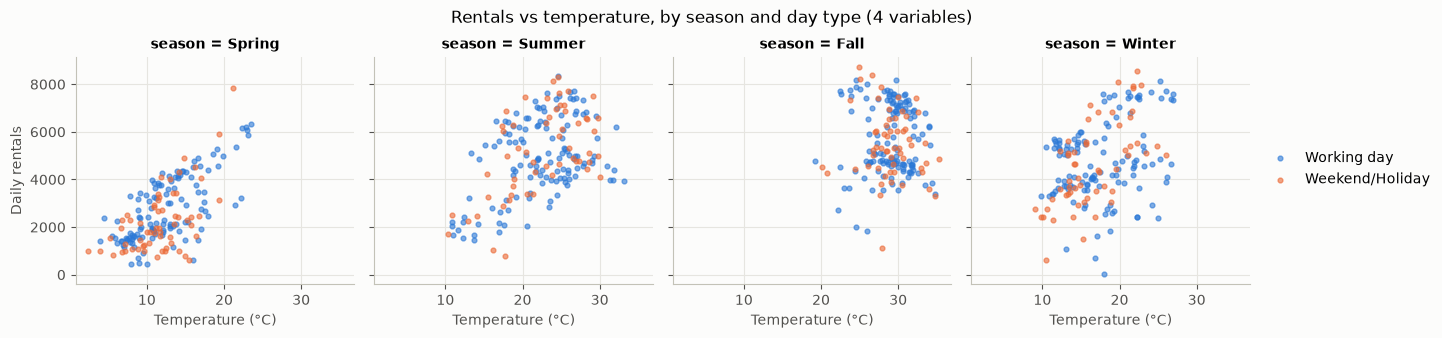

In [18]:
g = sns.FacetGrid(daily.reset_index(), col="season", col_order=SEASONS, hue="day_type",
                  hue_order=["Working day", "Weekend/Holiday"], palette=PALETTE[:2], height=3.2)
g.map(plt.scatter, "temp", "cnt", s=12, alpha=0.6)
g.add_legend(title="")
g.set_axis_labels("Temperature (°C)", "Daily rentals")
g.figure.suptitle("Rentals vs temperature, by season and day type (4 variables)", y=1.04)
save_fig(g.figure, "03_facet_nd")
plt.show()

Rentals rise with temperature in every season, but in **Fall** very hot days do not add demand (and humid/rainy days drop sharply) — the effect of one variable depends on the others, which is why n-D analysis matters.

## 7. Visualization: scatter plots, dot charts, bar plots
### 7.1 Scatter plots

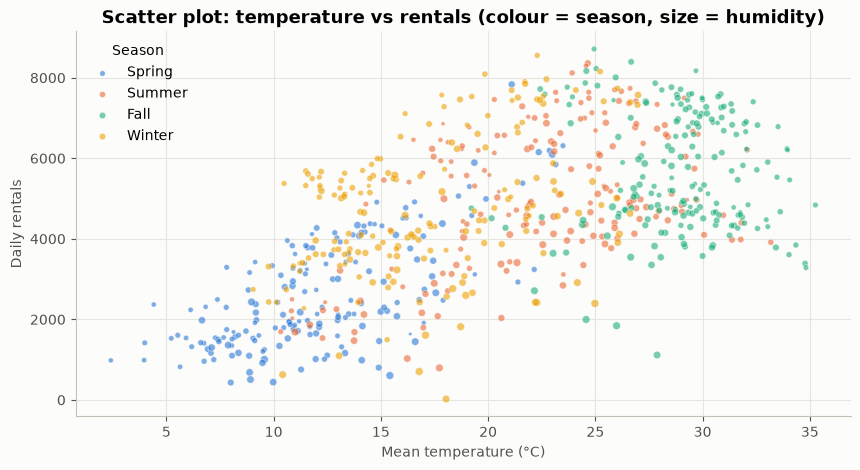

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
for i, s in enumerate(SEASONS):
    d = daily[daily.season == s]
    ax.scatter(d["temp"], d["cnt"], s=d["humidity"] / 3, alpha=0.6, color=PALETTE[i], label=s,
               edgecolor="#fcfcfb", linewidth=0.5)
ax.set_xlabel("Mean temperature (°C)")
ax.set_ylabel("Daily rentals")
ax.set_title("Scatter plot: temperature vs rentals (colour = season, size = humidity)")
ax.legend(title="Season")
save_fig(fig, "03_scatter")
plt.show()

### 7.2 Dot charts
A Cleveland dot chart shows a value per category with a dot instead of a bar — cleaner when comparing many categories or two groups.

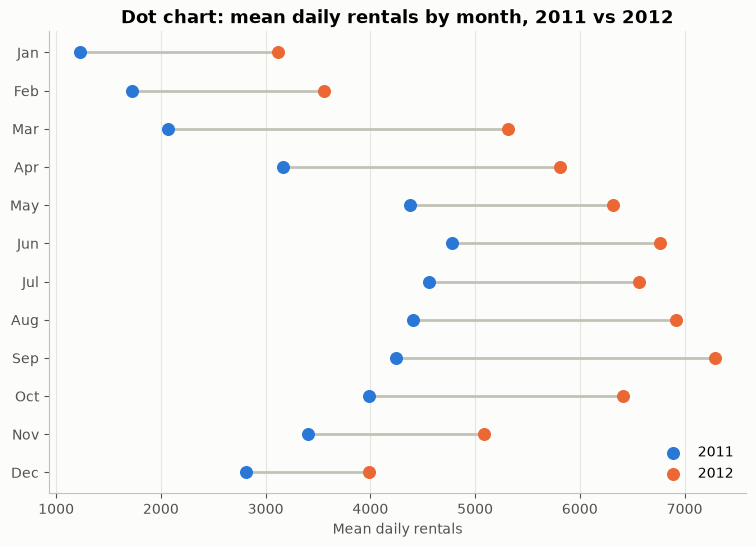

In [20]:
m = daily.groupby(["month", "year"])["cnt"].mean().unstack()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(12)
ax.hlines(y, m[2011], m[2012], color="#c3c2b7", linewidth=2)
ax.scatter(m[2011], y, color=PALETTE[0], s=70, zorder=3, label="2011")
ax.scatter(m[2012], y, color=PALETTE[1], s=70, zorder=3, label="2012")
ax.set_yticks(y, months)
ax.invert_yaxis()
ax.set_xlabel("Mean daily rentals")
ax.set_title("Dot chart: mean daily rentals by month, 2011 vs 2012")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "03_dot_chart")
plt.show()

### 7.3 Bar plots — simple, grouped and stacked

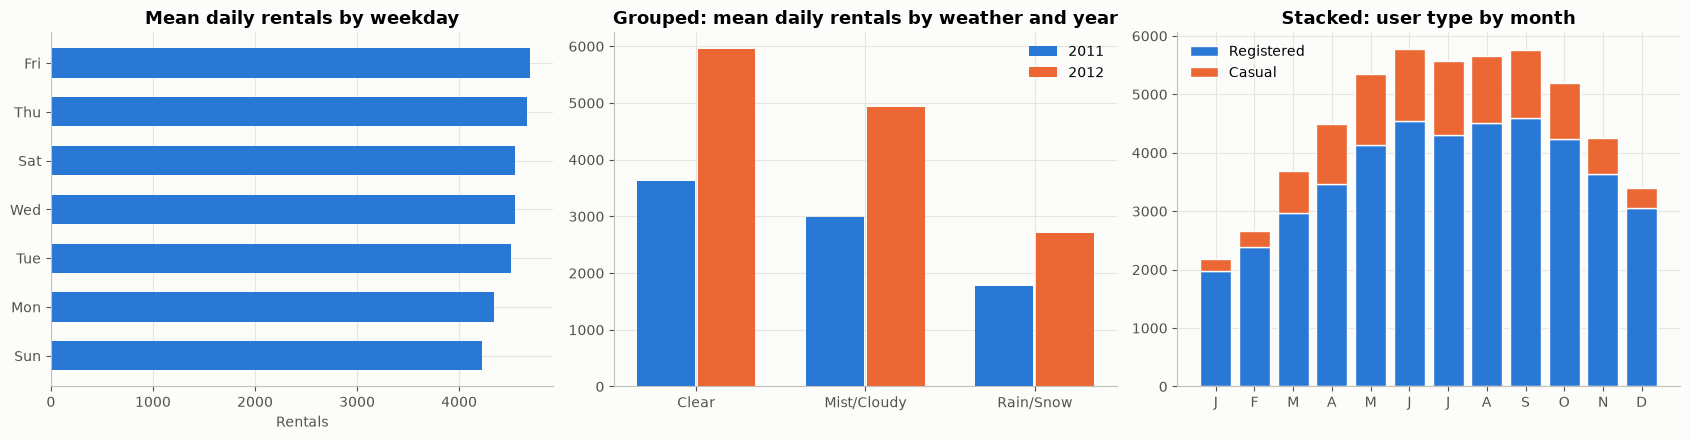

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Simple (sorted, horizontal)
wd = daily.groupby("weekday")["cnt"].mean().reindex(WEEKDAYS).sort_values()
axes[0].barh(wd.index, wd.values, color=PALETTE[0], height=0.6)
axes[0].set_title("Mean daily rentals by weekday")
axes[0].set_xlabel("Rentals")

# Grouped
grp = daily.groupby(["weather", "year"])["cnt"].mean().unstack().reindex(WEATHER)
x = np.arange(len(grp))
axes[1].bar(x - 0.18, grp[2011], width=0.34, color=PALETTE[0], label="2011")
axes[1].bar(x + 0.18, grp[2012], width=0.34, color=PALETTE[1], label="2012")
axes[1].set_xticks(x, grp.index)
axes[1].set_title("Grouped: mean daily rentals by weather and year")
axes[1].legend()

# Stacked
stk = daily.groupby("month")[["registered", "casual"]].mean()
axes[2].bar(stk.index, stk["registered"], color=PALETTE[0], label="Registered", edgecolor="#fcfcfb")
axes[2].bar(stk.index, stk["casual"], bottom=stk["registered"], color=PALETTE[1], label="Casual", edgecolor="#fcfcfb")
axes[2].set_xticks(range(1, 13), [mo[0] for mo in months])
axes[2].set_title("Stacked: user type by month")
axes[2].legend()
fig.tight_layout()
save_fig(fig, "03_bar_plots")
plt.show()

## Summary
- Daily demand ≈ 4,500 rides on average; **casual** demand is far more volatile than **registered** demand.
- Derived feature `casual_share` reveals that weekends change *who* rides more than *how many* ride.
- Daily rentals are not normal — they form a broad, two-regime (winter vs summer) distribution.
- Contingency tables + χ² show temperature band and demand level are clearly associated (V ≈ 0.24), while season and weather type are only weakly related (V ≈ 0.11).
- n-D views (pivot tables, facets) show interactions between season, day type, weather and temperature.
- Bad weather cuts demand sharply, and every month of 2012 beat the same month of 2011.